# Problem Definition
Loan approval is a critical process for financial institutions. This project aims to build a machine learning model that predicts whether a loan application will be approved based on applicant information such as income, education, credit history, employment status, and loan amount.
## Project Objective
The objective of this project is to develop a reliable classification model that can assist lenders in making faster and more accurate loan approval decisions while reducing the risk of loan default.
### Problem Type
**Binary Classification**
- **1** = Loan Approved
- **0** = Loan Not Approved

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
df = pd.read_csv(r"C:\Users\User\OneDrive/Desktop/Webfala/Machine_Learning/Data/loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Exploratory Data Analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
df_copy

In [7]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [10]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [4]:
df_copy = df.copy()

In [5]:
# Checking for duplicates
df_copy.duplicated().sum()

np.int64(0)

In [6]:
df_copy['Gender'] = df_copy['Gender'].fillna(df_copy['Gender'].mode()[0])
df_copy['Married'] = df_copy['Married'].fillna(df_copy['Married'].mode()[0])
df_copy['Dependents'] = df_copy['Dependents'].fillna(df_copy['Dependents'].mode()[0])
df_copy['Self_Employed'] = df_copy['Self_Employed'].fillna(df_copy['Self_Employed'].mode()[0])

In [7]:
df_copy['LoanAmount'] = df_copy['LoanAmount'].fillna(df_copy['LoanAmount'].median())
df_copy['Credit_History'] = df_copy['Credit_History'].fillna(df_copy['Credit_History'].median())
df_copy['Loan_Amount_Term'] = df_copy['Loan_Amount_Term'].fillna(df_copy['Loan_Amount_Term'].median())

In [10]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [8]:
df_copy.drop('Loan_ID', axis=1, inplace=True)

In [59]:
df_copy

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [84]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    int64  
 1   Married            614 non-null    int64  
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    int64  
 4   Self_Employed      614 non-null    int64  
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         614 non-null    float64
 8   Loan_Amount_Term   614 non-null    float64
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    int64  
 11  Loan_Status        614 non-null    int64  
dtypes: float64(4), int64(8)
memory usage: 57.7 KB


In [9]:
df_copy['Dependents'] = df_copy['Dependents'].replace('3+', 3)
df_copy['Dependents'] = df_copy['Dependents'].astype(int)

#### Loan Status Distribution

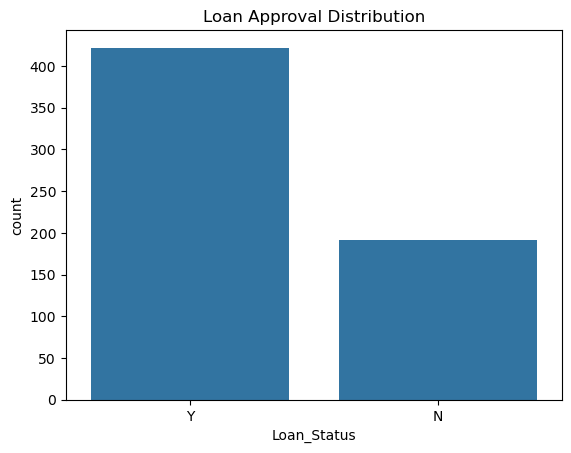

In [10]:
sns.countplot(x='Loan_Status', data=df)
plt.title('Loan Approval Distribution')
plt.show()

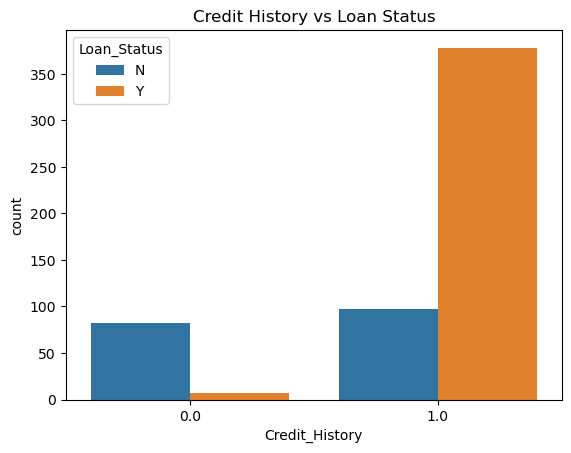

In [65]:
sns.countplot(x='Credit_History', hue='Loan_Status', data=df)
plt.title('Credit History vs Loan Status')
plt.show()

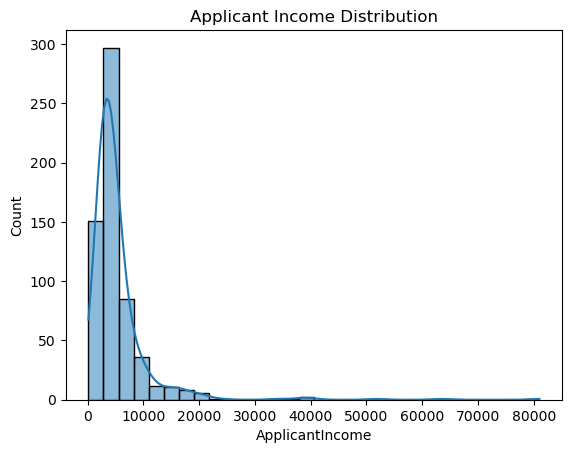

In [66]:
sns.histplot(df['ApplicantIncome'], bins=30, kde=True)
plt.title('Applicant Income Distribution')
plt.show()

## Encoding

In [11]:
df_copy['Gender'] = df_copy['Gender'].map({'Male': 1, 'Female': 0})
df_copy['Married'] = df_copy['Married'].map({'Yes': 1, 'No': 0})
df_copy['Education'] = df_copy['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df_copy['Self_Employed'] = df_copy['Self_Employed'].map({'Yes': 1, 'No': 0})
df_copy['Loan_Status'] = df_copy['Loan_Status'].map({'Y': 1, 'N': 0})
df_copy['Property_Area'] = df_copy['Property_Area'].map({
    'Rural': 0,
    'Semiurban': 1,
    'Urban': 2
})

###  Feature Selection

In [12]:
X = df_copy.drop('Loan_Status', axis=1)
y = df_copy['Loan_Status']

In [13]:
X

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,2
1,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0
2,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,2
3,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,2
4,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,2
...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,1,0,2900,0.0,71.0,360.0,1.0,0
610,1,1,3,1,0,4106,0.0,40.0,180.0,1.0,0
611,1,1,1,1,0,8072,240.0,253.0,360.0,1.0,2
612,1,1,2,1,0,7583,0.0,187.0,360.0,1.0,2


In [14]:
y

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [16]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (491, 11)
Testing data: (123, 11)


In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
y

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

### Train Logistic Regression

In [18]:
logistic = LogisticRegression(max_iter=1000)
logistic.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


#### Model Evaluation

In [19]:
log_prediction = logistic.predict(X_test_scaled)
logistic_accuracy = accuracy_score(log_prediction, y_test)
print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.8617886178861789


In [20]:
print(classification_report(log_prediction, y_test))

              precision    recall  f1-score   support

           0       0.58      0.96      0.72        23
           1       0.99      0.84      0.91       100

    accuracy                           0.86       123
   macro avg       0.78      0.90      0.81       123
weighted avg       0.91      0.86      0.87       123



### Train Decision Tree

In [21]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


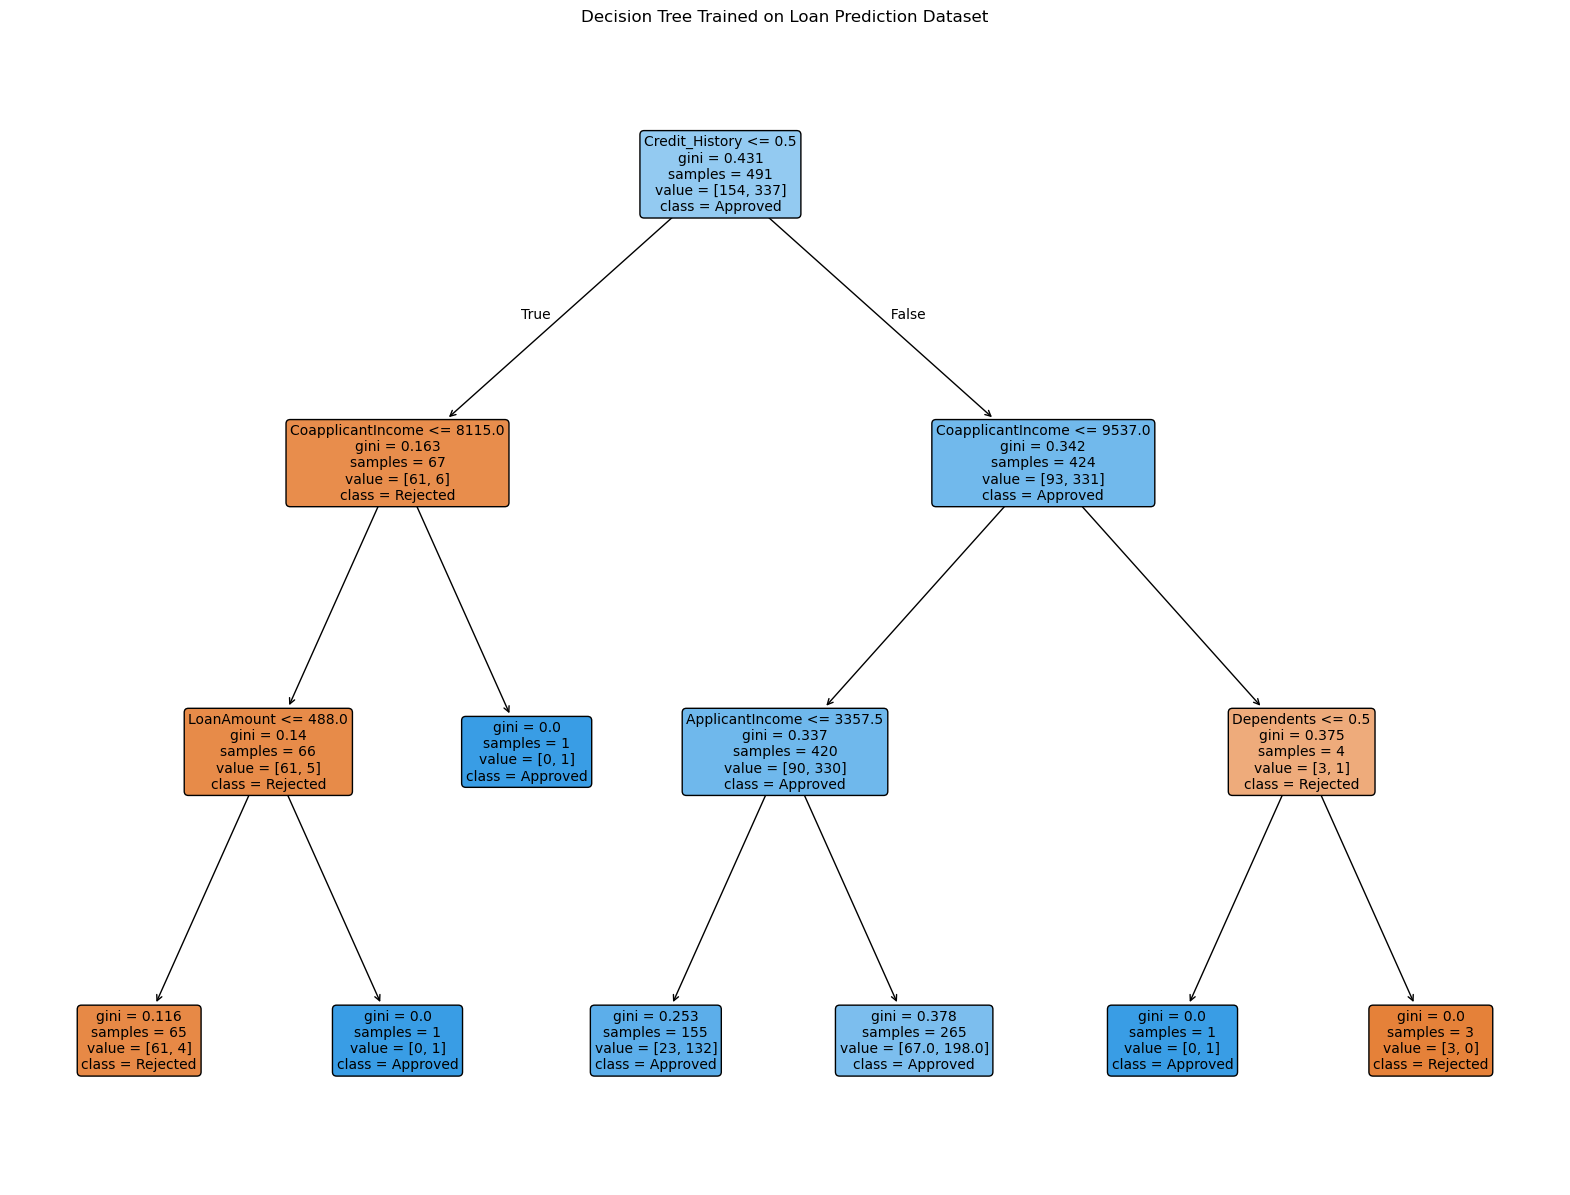

In [22]:
plt.figure(figsize=(20,15))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=['Rejected', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Decision Tree Trained on Loan Prediction Dataset')
plt.show()

### Model Evaluation 

In [23]:
tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8455284552845529


In [24]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       0.95      0.53      0.68        38
           1       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



### Train Random Forest

In [25]:
forest_model = RandomForestClassifier(
    random_state=42,
    n_estimators =100,
    max_depth=3
)
forest_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [26]:
forest_predictions = forest_model.predict(X_test)
forest_accuracy= accuracy_score(
    y_test,
    forest_predictions
)
print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.8536585365853658


In [27]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



#### Parameter tuning

In [28]:
forest_model_2 = RandomForestClassifier(
    random_state=42,
    n_estimators=200,
    max_depth=8
)
forest_model_2.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
forest_predictions_2 = forest_model_2.predict(X_test)

forest_accuracy_2 = accuracy_score(
    y_test,
    forest_predictions_2
)
print("Random Forest Accuracy:", forest_accuracy_2)

Random Forest Accuracy: 0.8617886178861789


### Using Grid search

In [ ]:
# Tune the Random Forest
forest_params = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [3, 5, 7, 8,10]
}

forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_params,
    cv=5,
    scoring = "accuracy"
)

forest_grid.fit(X_train, y_train)

In [ ]:
print("Best Parameters:")
print(forest_grid.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(forest_grid.best_score_)

### Train SVM

In [ ]:
from sklearn.svm import SVC

In [ ]:
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled, y_train)

In [43]:
svm_predict = svm_model.predict(X_test_scaled)
svm_accuracy= accuracy_score(y_test, svm_predict)

print("Accuracy:", svm_accuracy)

Accuracy: 0.8536585365853658


In [44]:
## Lets compare out the models
results = pd.DataFrame({
 "Model": [
 "Logistic Regression",
 "Decision Tree",
 "Random Forest",
 "Random Forest2",
 "SVM"
 ],
 "Accuracy": [
 logistic_accuracy,
 tree_accuracy,
 forest_accuracy,
 forest_accuracy_2,
 svm_accuracy]
 })
results

,Model,Accuracy
0,Logistic Regression,0.861789
1,Decision Tree,0.845528
2,Random Forest,0.853659
3,Random Forest2,0.861789
4,SVM,0.853659


In [45]:
results["Accuracy"] = results["Accuracy"] * 100
results["Accuracy"] = results["Accuracy"].round(2)

results.sort_values(by="Accuracy", ascending=False, inplace=True)

results

,Model,Accuracy
0,Logistic Regression,86.18
3,Random Forest2,86.18
2,Random Forest,85.37
4,SVM,85.37
1,Decision Tree,84.55


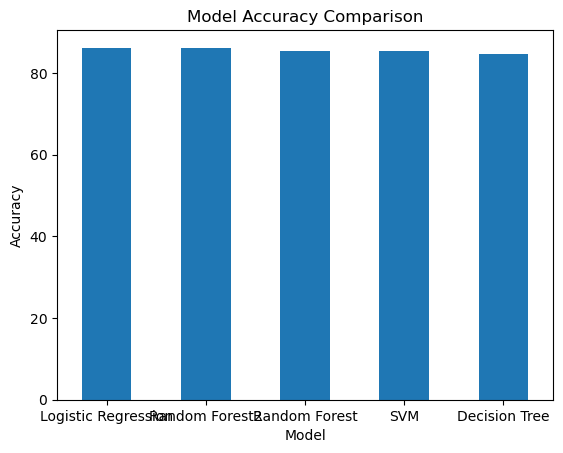

In [46]:
results.plot(
 x="Model",
 y="Accuracy",
 kind="bar",
 legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

In [47]:
confusion_matrix(y_test, log_prediction)

array([[22, 16],
       [ 1, 84]])

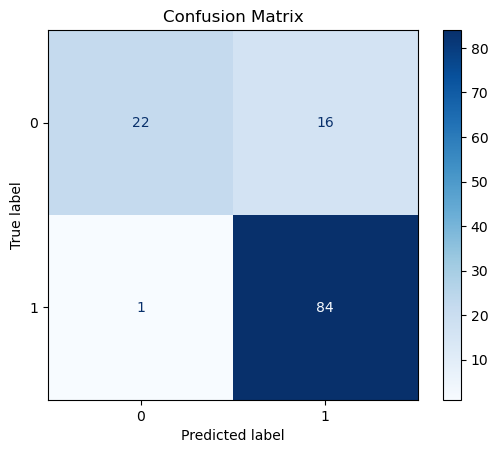

In [48]:
cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, log_prediction))
cm_display.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()